# 09. 옵션 Greeks와 Delta hedging

옵션가격이 입력값에 얼마나 민감한지 계산하고, Delta를 이용한 동적 헤지를 실습합니다.
강의록의 모든 프로그램과 비교용 출력을 원문 순서대로 수록했습니다.

**사용 방법:** 압축을 푼 폴더에서 노트북을 열고 **Restart Kernel → Run All**을 실행하세요.
같은 폴더의 `pricing_models.py`에서 앞 장의 경로생성·PDE·Heston Monte Carlo 함수를 가져옵니다.
따라서 앞 장 노트북의 실행 상태에 의존하지 않습니다. 저장된 표와 그림은 실제 실행 결과입니다.

**학습 순서**

1. Black–Scholes 해석적 Greeks와 단위
2. 중심차분(bump-and-revalue)과 오차
3. 한 경로의 Delta hedge와 헤지 빈도
4. 포트폴리오 Greeks, CEV 격자 Greeks, Heston Monte Carlo Greeks

$\Delta=\partial V/\partial S$, $\Gamma=\partial^2V/\partial S^2$입니다.
여기서 Theta는 달력시간 증가에 대한 민감도 $\partial V/\partial t=-\partial V/\partial\tau$입니다.
Vega와 Rho는 원 단위 민감도이므로 **1%p 변화**를 표시하려면 $0.01$을 곱합니다.

**계산시간:** 마지막 Heston 예제는 원문대로 가격평가마다 200,000개 경로와 252개 시간단계를 사용합니다.
여러 번 재평가하므로 일반적인 노트북에서는 다른 셀보다 오래 걸립니다.

In [1]:
%matplotlib inline

### 이번 장에서 사용할 라이브러리 불러오기

그림, 배열, 표와 표준정규분포 함수를 준비합니다.

원문: `section09_option_greeks.tex` · Listing 1 · 141행

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.stats import norm

### 강의록 Listing 2

제공된 공통 모듈에서 앞 장의 정의만 가져옵니다. 앞 장의 예제 전체를 다시 실행하지는 않습니다.

원문: `section09_option_greeks.tex` · Listing 2 · 156행

In [3]:
from pricing_models import simulate_gbm_paths
from pricing_models import local_volatility_pde_price
from pricing_models import monte_carlo_heston_option

### Black–Scholes 유럽형 옵션가격 함수

수치미분의 기준 가격함수입니다. 입력값을 float로 변환하고 유효성을 검사합니다.

원문: `section09_option_greeks.tex` · Listing 3 · 250행

In [4]:
def black_scholes_price(
    spot,
    strike,
    maturity,
    rate,
    volatility,
    dividend_yield=0.0,
    option_type="call",
):
    spot = float(spot)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    volatility = float(volatility)
    dividend_yield = float(dividend_yield)
    option_type = str(option_type).lower()

    parameters = [spot, strike, maturity, rate, volatility, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")

    if spot <= 0.0 or strike <= 0.0:
        raise ValueError("spot and strike must be positive")
    if maturity <= 0.0 or volatility <= 0.0:
        raise ValueError("maturity and volatility must be positive")

    sqrt_maturity = np.sqrt(maturity)
    d1 = (
        np.log(spot / strike)
        + (rate - dividend_yield + 0.5 * volatility**2) * maturity
    ) / (volatility * sqrt_maturity)
    d2 = d1 - volatility * sqrt_maturity

    discounted_spot = spot * np.exp(-dividend_yield * maturity)
    discounted_strike = strike * np.exp(-rate * maturity)

    if option_type == "call":
        price = discounted_spot * norm.cdf(d1) - discounted_strike * norm.cdf(d2)
    elif option_type == "put":
        price = discounted_strike * norm.cdf(-d2) - discounted_spot * norm.cdf(-d1)
    else:
        raise ValueError("option_type must be call or put")

    return float(price)

### Black–Scholes Greeks 함수

해석적 공식으로 Delta, Gamma, Vega, Theta, Rho를 한 번에 반환합니다.

원문: `section09_option_greeks.tex` · Listing 4 · 297행

In [5]:
def black_scholes_greeks(
    spot,
    strike,
    maturity,
    rate,
    volatility,
    dividend_yield=0.0,
    option_type="call",
):
    spot = float(spot)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    volatility = float(volatility)
    dividend_yield = float(dividend_yield)
    option_type = str(option_type).lower()

    parameters = [spot, strike, maturity, rate, volatility, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")

    if spot <= 0.0 or strike <= 0.0:
        raise ValueError("spot and strike must be positive")
    if maturity <= 0.0 or volatility <= 0.0:
        raise ValueError("maturity and volatility must be positive")

    sqrt_maturity = np.sqrt(maturity)
    d1 = (
        np.log(spot / strike)
        + (rate - dividend_yield + 0.5 * volatility**2) * maturity
    ) / (volatility * sqrt_maturity)
    d2 = d1 - volatility * sqrt_maturity

    discount_stock = np.exp(-dividend_yield * maturity)
    discount_strike = np.exp(-rate * maturity)
    density_d1 = norm.pdf(d1)

    gamma = discount_stock * density_d1 / (spot * volatility * sqrt_maturity)
    vega = spot * discount_stock * density_d1 * sqrt_maturity

    if option_type == "call":
        delta = discount_stock * norm.cdf(d1)
        theta = -spot * discount_stock * density_d1 * volatility / (2.0 * sqrt_maturity)
        theta -= rate * strike * discount_strike * norm.cdf(d2)
        theta += dividend_yield * spot * discount_stock * norm.cdf(d1)
        rho = strike * maturity * discount_strike * norm.cdf(d2)
    elif option_type == "put":
        delta = discount_stock * (norm.cdf(d1) - 1.0)
        theta = -spot * discount_stock * density_d1 * volatility / (2.0 * sqrt_maturity)
        theta += rate * strike * discount_strike * norm.cdf(-d2)
        theta -= dividend_yield * spot * discount_stock * norm.cdf(-d1)
        rho = -strike * maturity * discount_strike * norm.cdf(-d2)
    else:
        raise ValueError("option_type must be call or put")

    return {
        "delta": float(delta),
        "gamma": float(gamma),
        "vega": float(vega),
        "theta": float(theta),
        "rho": float(rho),
    }

### 콜옵션 Greeks 계산 예

원 단위 민감도와 1%p 또는 1일 기준 민감도를 구분하세요. Theta의 1일 환산은 365일 기준입니다.

원문: `section09_option_greeks.tex` · Listing 5 · 362행

In [6]:
call_greeks = black_scholes_greeks(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.05,
    volatility=0.20,
)

print(f"Delta: {call_greeks['delta']:.6f}")
print(f"Gamma: {call_greeks['gamma']:.6f}")
print(f"Vega: {call_greeks['vega']:.6f}")
print(f"Theta: {call_greeks['theta']:.6f}")
print(f"Rho: {call_greeks['rho']:.6f}")
print(f"Vega per 1 point: {0.01 * call_greeks['vega']:.6f}")
print(f"Theta per day: {call_greeks['theta'] / 365.0:.6f}")
print(f"Rho per 1 point: {0.01 * call_greeks['rho']:.6f}")

Delta: 0.636831
Gamma: 0.018762
Vega: 37.524035
Theta: -6.414028
Rho: 53.232482
Vega per 1 point: 0.375240
Theta per day: -0.017573
Rho per 1 point: 0.532325


**강의록 Listing 6**

강의록에 실린 비교용 출력입니다. 위 코드 셀의 출력은 이 노트북을 실제 실행해서 저장한 결과입니다.

```text
Delta: 0.636831
Gamma: 0.018762
Vega: 37.524035
Theta: -6.414028
Rho: 53.232482
Vega per 1 point: 0.375240
Theta per day: -0.017573
Rho per 1 point: 0.532325
```

### 주가에 따른 Delta 계산

콜옵션의 Delta가 주가에 따라 0에서 1 쪽으로 변하는 모양을 확인합니다.

원문: `section09_option_greeks.tex` · Listing 7 · 396행

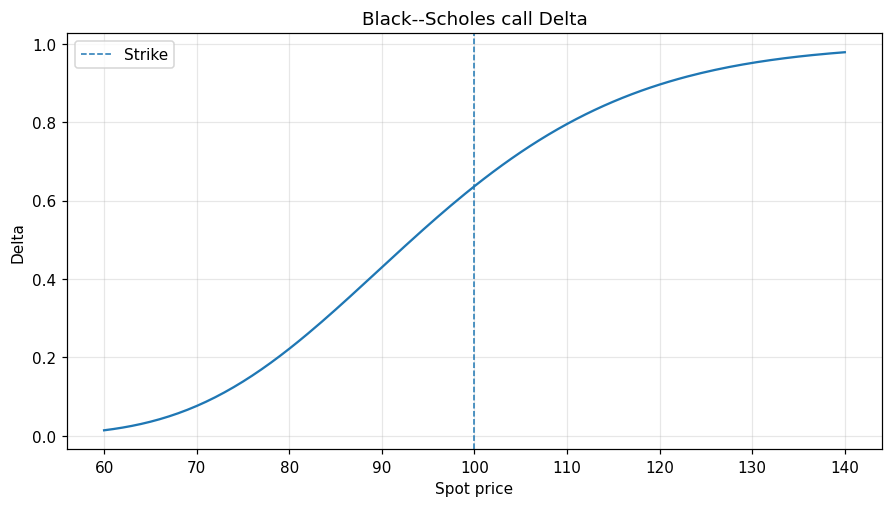

In [7]:
spot_values = np.linspace(60.0, 140.0, num=161)

delta_values = [
    black_scholes_greeks(
        spot=spot,
        strike=100.0,
        maturity=1.0,
        rate=0.05,
        volatility=0.20,
    )["delta"]
    for spot in spot_values
]

fig, ax = plt.subplots(figsize=(8.0, 4.5), layout="constrained")
ax.plot(spot_values, delta_values)
ax.axvline(100.0, linestyle="--", linewidth=1.0, label="Strike")
ax.set_title("Black--Scholes call Delta")
ax.set_xlabel("Spot price")
ax.set_ylabel("Delta")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

### 주가에 따른 Gamma 계산

Gamma는 Delta의 변화율입니다. Delta 곡선의 기울기가 큰 곳과 비교하세요.

원문: `section09_option_greeks.tex` · Listing 8 · 421행

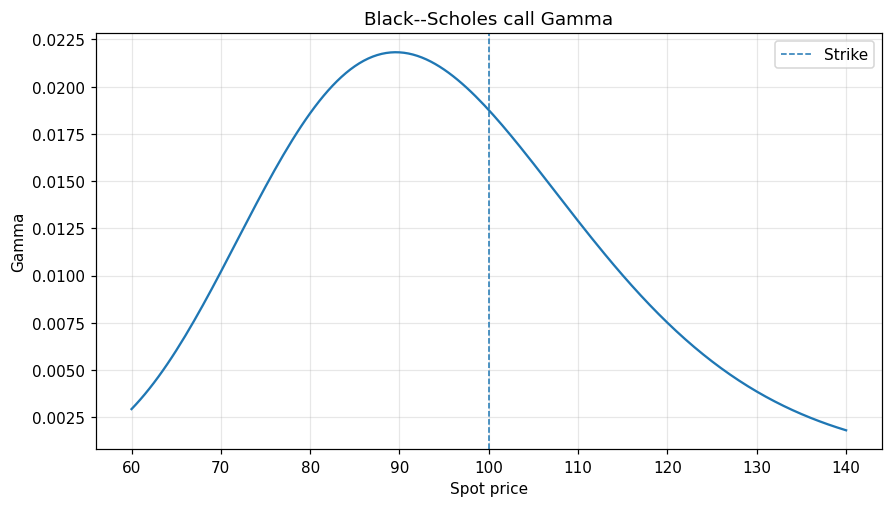

In [8]:
gamma_values = [
    black_scholes_greeks(
        spot=spot,
        strike=100.0,
        maturity=1.0,
        rate=0.05,
        volatility=0.20,
    )["gamma"]
    for spot in spot_values
]

fig, ax = plt.subplots(figsize=(8.0, 4.5), layout="constrained")
ax.plot(spot_values, gamma_values)
ax.axvline(100.0, linestyle="--", linewidth=1.0, label="Strike")
ax.set_title("Black--Scholes call Gamma")
ax.set_xlabel("Spot price")
ax.set_ylabel("Gamma")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

### 중심차분으로 Greeks 계산하기

같은 가격함수를 입력값만 조금씩 바꾸어 호출합니다. Theta의 부호 때문에 남은 만기는 반대 방향으로 움직입니다.

원문: `section09_option_greeks.tex` · Listing 9 · 485행

In [9]:
def finite_difference_greeks(
    price_function,
    spot,
    strike,
    maturity,
    rate,
    volatility,
    dividend_yield=0.0,
    option_type="call",
    spot_bump=None,
    volatility_bump=1.0e-4,
    rate_bump=1.0e-4,
    time_bump=None,
):
    spot = float(spot)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    volatility = float(volatility)
    dividend_yield = float(dividend_yield)

    if spot_bump is None:
        spot_bump = max(1.0e-3 * spot, 1.0e-6)
    if time_bump is None:
        time_bump = min(1.0 / 365.0, maturity / 4.0)

    spot_bump = float(spot_bump)
    volatility_bump = float(volatility_bump)
    rate_bump = float(rate_bump)
    time_bump = float(time_bump)

    inputs = [spot, strike, maturity, rate, volatility, dividend_yield]
    bumps = [spot_bump, volatility_bump, rate_bump, time_bump]
    if not np.isfinite(inputs + bumps).all():
        raise ValueError("inputs and bumps must be finite")
    if min(spot, strike, maturity, volatility) <= 0.0 or min(bumps) <= 0.0:
        raise ValueError("prices, maturity, volatility and bumps must be positive")
    if spot <= spot_bump:
        raise ValueError("spot must be larger than spot_bump")
    if maturity <= time_bump:
        raise ValueError("maturity must be larger than time_bump")
    if volatility <= volatility_bump:
        raise ValueError("volatility must be larger than volatility_bump")

    def price(s, tau, r, sigma):
        return float(
            price_function(
                spot=s,
                strike=strike,
                maturity=tau,
                rate=r,
                volatility=sigma,
                dividend_yield=dividend_yield,
                option_type=option_type,
            )
        )

    base = price(spot, maturity, rate, volatility)
    price_spot_up = price(spot + spot_bump, maturity, rate, volatility)
    price_spot_down = price(spot - spot_bump, maturity, rate, volatility)

    delta = (price_spot_up - price_spot_down) / (2.0 * spot_bump)
    gamma = (price_spot_up - 2.0 * base + price_spot_down) / spot_bump**2

    price_vol_up = price(spot, maturity, rate, volatility + volatility_bump)
    price_vol_down = price(spot, maturity, rate, volatility - volatility_bump)
    vega = (price_vol_up - price_vol_down) / (2.0 * volatility_bump)

    price_rate_up = price(spot, maturity, rate + rate_bump, volatility)
    price_rate_down = price(spot, maturity, rate - rate_bump, volatility)
    rho = (price_rate_up - price_rate_down) / (2.0 * rate_bump)

    price_time_forward = price(spot, maturity - time_bump, rate, volatility)
    price_time_backward = price(spot, maturity + time_bump, rate, volatility)
    theta = (price_time_forward - price_time_backward) / (2.0 * time_bump)

    return {
        "delta": float(delta),
        "gamma": float(gamma),
        "vega": float(vega),
        "theta": float(theta),
        "rho": float(rho),
    }

### 해석적 Greeks와 수치 Greeks 비교

해석적 값과 수치미분값을 같은 표에서 비교합니다. 차이가 정확히 0이 아니라 작다는 점에 주목하세요.

원문: `section09_option_greeks.tex` · Listing 10 · 571행

In [10]:
analytic = black_scholes_greeks(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.05,
    volatility=0.20,
)

numerical = finite_difference_greeks(
    price_function=black_scholes_price,
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.05,
    volatility=0.20,
)

comparison = pd.DataFrame({"analytic": analytic, "numerical": numerical})
comparison["absolute_error"] = abs(comparison["analytic"] - comparison["numerical"])
print(comparison)

        analytic  numerical  absolute_error
delta   0.636831   0.636830    8.599222e-07
gamma   0.018762   0.018762    2.296498e-08
vega   37.524035  37.524034    3.044830e-07
theta  -6.414028  -6.414031    3.726611e-06
rho    53.232482  53.232481    7.712417e-07


**강의록 Listing 11**

강의록에 실린 비교용 출력입니다. 위 코드 셀의 출력은 이 노트북을 실제 실행해서 저장한 결과입니다.

```text
        analytic  numerical  absolute_error
delta   0.636831   0.636830    8.60e-07
gamma   0.018762   0.018762    2.30e-08
vega   37.524035  37.524034    3.04e-07
theta  -6.414028  -6.414031    3.73e-06
rho    53.232482  53.232481    7.71e-07
```

### 선택 연습 해설: spot bump와 수치미분 오차

원문 연습의 $h_S=10,1,0.1,0.01,0.001,0.0001$을 비교합니다.
Delta·Gamma만 비교하므로 이 보충 셀에서는 주가 방향의 세 가격만 계산합니다.
아주 작은 bump에서 반올림오차가 나타날 수 있습니다.

,spot_bump,delta,gamma,delta_error,gamma_error
0,10.0000,0.628587,0.018530,8.244068e-03,2.319306e-04
1,1.0000,0.636745,0.018760,8.595627e-05,2.296648e-06
2,0.1000,0.636830,0.018762,8.599222e-07,2.296498e-08
3,0.0100,0.636831,0.018762,8.599305e-09,2.681133e-10
4,0.0010,0.636831,0.018762,8.274015e-11,1.561584e-08
5,0.0001,0.636831,0.018762,6.077694e-12,1.364081e-07


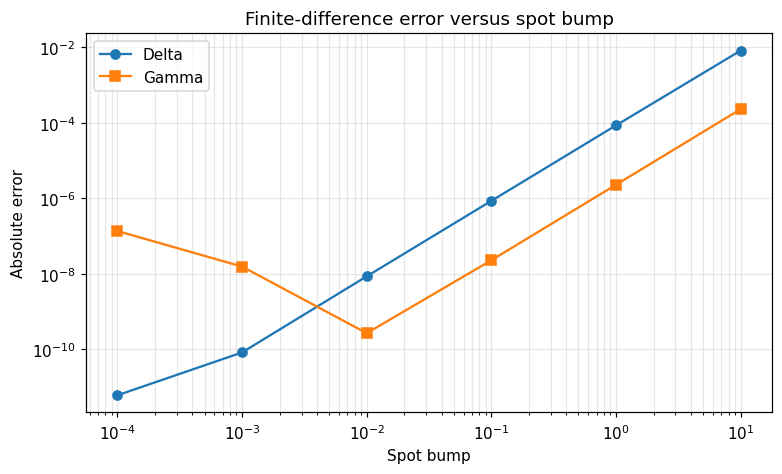

In [11]:
bump_rows = []
base_price = black_scholes_price(100.0, 100.0, 1.0, 0.05, 0.20)
for bump in [10.0, 1.0, 0.1, 0.01, 0.001, 0.0001]:
    up_price = black_scholes_price(100.0 + bump, 100.0, 1.0, 0.05, 0.20)
    down_price = black_scholes_price(100.0 - bump, 100.0, 1.0, 0.05, 0.20)
    delta_fd = (up_price - down_price) / (2.0 * bump)
    gamma_fd = (up_price - 2.0 * base_price + down_price) / bump**2
    bump_rows.append({
        "spot_bump": bump, "delta": delta_fd, "gamma": gamma_fd,
        "delta_error": abs(delta_fd - analytic["delta"]),
        "gamma_error": abs(gamma_fd - analytic["gamma"]),
    })
bump_results = pd.DataFrame(bump_rows)
display(bump_results)
fig, ax = plt.subplots(figsize=(7.0, 4.2), layout="constrained")
ax.loglog(bump_results["spot_bump"], bump_results["delta_error"], marker="o", label="Delta")
ax.loglog(bump_results["spot_bump"], bump_results["gamma_error"], marker="s", label="Gamma")
ax.set_xlabel("Spot bump")
ax.set_ylabel("Absolute error")
ax.set_title("Finite-difference error versus spot bump")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

### PDE 가격격자에서 Delta와 Gamma 계산하기

균등한 PDE 주가격자의 내부점에서 Delta와 Gamma를 구합니다. 경계점에는 이 중심차분 공식을 그대로 사용할 수 없습니다.

원문: `section09_option_greeks.tex` · Listing 12 · 669행

In [12]:
def pde_grid_delta_gamma(stock_grid, option_values, index):
    stock_grid = np.asarray(stock_grid, dtype=float)
    option_values = np.asarray(option_values, dtype=float)
    index = int(index)

    if index <= 0 or index >= stock_grid.size - 1:
        raise ValueError("index must be an interior grid point")

    left_step = stock_grid[index] - stock_grid[index - 1]
    right_step = stock_grid[index + 1] - stock_grid[index]

    if not np.isclose(left_step, right_step):
        raise ValueError("this function assumes a uniform grid")

    d_s = left_step
    delta = (option_values[index + 1] - option_values[index - 1]) / (2.0 * d_s)
    gamma = (
        option_values[index - 1] - 2.0 * option_values[index]
        + option_values[index + 1]
    ) / d_s**2

    return float(delta), float(gamma)

### Black–Scholes call Delta 함수

헤지 코드에서 사용할 콜 Delta를 별도 함수로 묶습니다.

원문: `section09_option_greeks.tex` · Listing 13 · 755행

In [13]:
def black_scholes_call_delta(spot, strike, maturity, rate, volatility):
    return black_scholes_greeks(
        spot=spot,
        strike=strike,
        maturity=maturity,
        rate=rate,
        volatility=volatility,
        option_type="call",
    )["delta"]

### 한 경로에서 short call Delta hedge

콜옵션을 매도한 포지션에 대해 Delta만큼 주식을 보유하고, 잔여 현금은 무위험이자율로 운용합니다. 거래비용과 배당은 이 예제에서 생략합니다.

원문: `section09_option_greeks.tex` · Listing 14 · 767행

In [14]:
def delta_hedge_short_call(stock_path, strike, maturity, rate, volatility):
    stock_path = np.asarray(stock_path, dtype=float)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    volatility = float(volatility)

    if stock_path.ndim != 1 or not np.isfinite(stock_path).all():
        raise ValueError("stock_path must be a finite one-dimensional array")
    if np.any(stock_path <= 0.0):
        raise ValueError("stock_path values must be positive")

    n_steps = stock_path.size - 1
    if n_steps <= 0:
        raise ValueError("stock_path must contain at least two values")

    dt = maturity / n_steps
    premium = black_scholes_price(
        spot=stock_path[0],
        strike=strike,
        maturity=maturity,
        rate=rate,
        volatility=volatility,
    )

    delta = black_scholes_call_delta(
        stock_path[0], strike, maturity, rate, volatility
    )
    cash = premium - delta * stock_path[0]

    for step in range(1, n_steps):
        cash *= np.exp(rate * dt)
        remaining_maturity = maturity - step * dt
        new_delta = black_scholes_call_delta(
            stock_path[step], strike, remaining_maturity, rate, volatility
        )
        cash -= (new_delta - delta) * stock_path[step]
        delta = new_delta

    cash *= np.exp(rate * dt)
    hedge_value = delta * stock_path[-1] + cash
    payoff = max(stock_path[-1] - strike, 0.0)
    hedging_error = hedge_value - payoff

    return {
        "premium": float(premium),
        "terminal_stock": float(stock_path[-1]),
        "payoff": float(payoff),
        "hedge_value": float(hedge_value),
        "hedging_error": float(hedging_error),
    }

### 한 개의 simulation 경로에서 Delta hedge 실행

위험중립측도 $\mathbb{Q}$의 한 모의 주가경로를 만든 뒤 헤지 오차를 계산합니다. 이 한 경로의 결과가 모든 경로의 성과를 대표하지는 않습니다.

원문: `section09_option_greeks.tex` · Listing 15 · 824행

In [15]:
time_grid, paths = simulate_gbm_paths(
    spot=100.0,
    maturity=1.0,
    rate=0.05,
    volatility=0.20,
    n_paths=1,
    n_steps=252,
    seed=2026,
)

hedge_result = delta_hedge_short_call(
    stock_path=paths[:, 0],
    strike=100.0,
    maturity=1.0,
    rate=0.05,
    volatility=0.20,
)

print(hedge_result)

{'premium': 10.450583572185565, 'terminal_stock': 131.09116396367241, 'payoff': 31.091163963672415, 'hedge_value': 30.632625742992886, 'hedging_error': -0.45853822067952876}


### 강의록 Listing 16

1008단계로 생성한 하나의 원경로를 공통으로 사용합니다. 빈도별로 같은 시작점·종점을 비교해야 경로 차이와 헤지 빈도 효과를 혼동하지 않습니다. 단일 경로에서 오차가 반드시 단조 감소하는 것은 아닙니다.

원문: `section09_option_greeks.tex` · Listing 16 · 862행

In [16]:
_, fine_paths = simulate_gbm_paths(
    spot=100.0,
    maturity=1.0,
    rate=0.05,
    volatility=0.20,
    n_paths=1,
    n_steps=1008,
    seed=2026,
)
fine_path = fine_paths[:, 0]

for count in [12, 48, 252, 1008]:
    stride = 1008 // count
    observed_path = fine_path[::stride]
    hedge_result = delta_hedge_short_call(
        stock_path=observed_path,
        strike=100.0,
        maturity=1.0,
        rate=0.05,
        volatility=0.20,
    )
    print(count, hedge_result["hedging_error"])

12 0.9597977955763213
48 -0.3611798291379813
252 -0.6915152783626866
1008 -0.22767685230964219


**보충 그림: 헤지에 사용한 원경로**

매번 새로운 경로를 생성하지 않고, 아래 경로의 관측 간격만 바꾸었습니다.

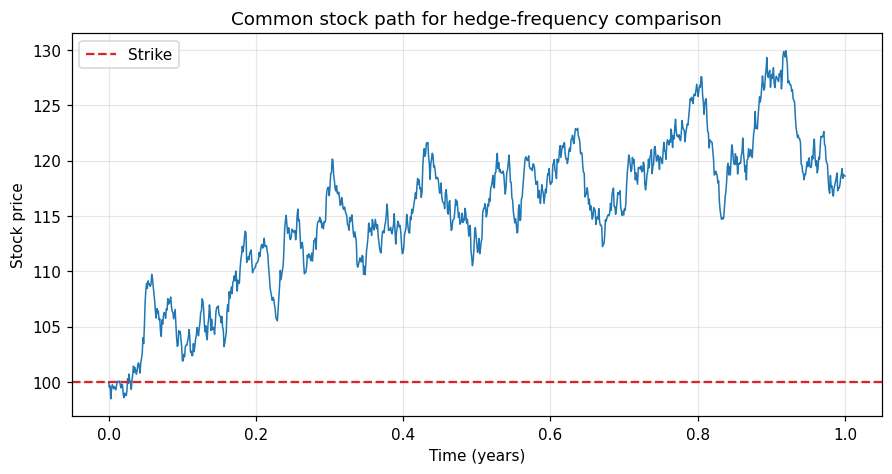

In [17]:
fig, ax = plt.subplots(figsize=(8.0, 4.2), layout="constrained")
ax.plot(np.linspace(0.0, 1.0, fine_path.size), fine_path, linewidth=1.0)
ax.axhline(100.0, color="tab:red", linestyle="--", label="Strike")
ax.set_xlabel("Time (years)")
ax.set_ylabel("Stock price")
ax.set_title("Common stock path for hedge-frequency comparison")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

### 포트폴리오 Greeks 합산 예

포지션 수량과 각 상품의 Greek를 곱해 합산합니다. 주식의 Gamma와 Vega는 이 예에서 0입니다.

원문: `section09_option_greeks.tex` · Listing 17 · 942행

In [18]:
positions = np.array([10.0, -5.0, 2.0])
deltas = np.array([0.60, -0.35, 1.00])
gammas = np.array([0.020, 0.015, 0.000])
vegas = np.array([35.0, 28.0, 0.0])

portfolio_delta = float(positions @ deltas)
portfolio_gamma = float(positions @ gammas)
portfolio_vega = float(positions @ vegas)

print(portfolio_delta, portfolio_gamma, portfolio_vega)

9.75 0.125 210.0


### 가격과 전체 격자를 반환하는 CEV PDE 함수

CEV의 기준주가와 beta를 고정한 채 PDE 가격곡선 전체를 반환합니다.

원문: `section09_option_greeks.tex` · Listing 18 · 1020행

In [19]:
def cev_pde_solution(
    spot,
    strike,
    maturity,
    rate,
    volatility,
    dividend_yield=0.0,
    option_type="call",
    beta=0.80,
    spot_reference=100.0,
):
    sigma_reference = float(volatility)
    beta = float(beta)
    spot_reference = float(spot_reference)

    parameters = [sigma_reference, beta, spot_reference]
    if not np.isfinite(parameters).all():
        raise ValueError("CEV parameters must be finite")
    if sigma_reference <= 0.0 or spot_reference <= 0.0:
        raise ValueError("sigma and reference must be positive")
    if not 0.0 < beta <= 1.0:
        raise ValueError("this exercise requires 0 < beta <= 1")

    def cev_local_volatility(time, stock):
        del time
        return sigma_reference * (stock / spot_reference) ** (beta - 1.0)

    return local_volatility_pde_price(
        spot=spot,
        strike=strike,
        maturity=maturity,
        rate=rate,
        s_max=300.0,
        n_space=400,
        n_time=1000,
        local_volatility=cev_local_volatility,
        option_type=option_type,
        dividend_yield=dividend_yield,
    )

### CEV 격자 Greeks와 변동성 민감도 계산

Delta와 Gamma는 격자에서 계산한 뒤 현재 주가에 보간합니다. Vega는 기준변동성을 bump하여 재평가합니다.

원문: `section09_option_greeks.tex` · Listing 19 · 1062행

In [20]:
cev_inputs = {
    "spot": 100.0,
    "strike": 100.0,
    "maturity": 1.0,
    "rate": 0.05,
    "volatility": 0.20,
    "beta": 0.80,
    "spot_reference": 100.0,
}
price, cev_grid, cev_values = cev_pde_solution(**cev_inputs)
inner_grid = cev_grid[1:-1]

grid_greeks = np.array([
    pde_grid_delta_gamma(cev_grid, cev_values, index)
    for index in range(1, cev_grid.size - 1)
])
delta = float(np.interp(cev_inputs["spot"], inner_grid, grid_greeks[:, 0]))
gamma = float(np.interp(cev_inputs["spot"], inner_grid, grid_greeks[:, 1]))

h_vol = 0.001
up_inputs = cev_inputs.copy()
down_inputs = cev_inputs.copy()
up_inputs["volatility"] += h_vol
down_inputs["volatility"] -= h_vol
up_price = cev_pde_solution(**up_inputs)[0]
down_price = cev_pde_solution(**down_inputs)[0]
vega = (up_price - down_price) / (2.0 * h_vol)

cev_greeks = {"price": price, "delta": delta, "gamma": gamma, "vega": vega}
print(cev_greeks)

{'price': 10.451011461764791, 'delta': 0.6292199807449409, 'gamma': 0.018960956165750952, 'vega': 37.522330626212685}


**보충 그림: CEV 격자에서 읽은 Delta와 Gamma**

앞 셀에서 계산한 한 가격곡선을 재사용합니다. 각 주가마다 PDE 전체를 다시 풀 필요가 없습니다.

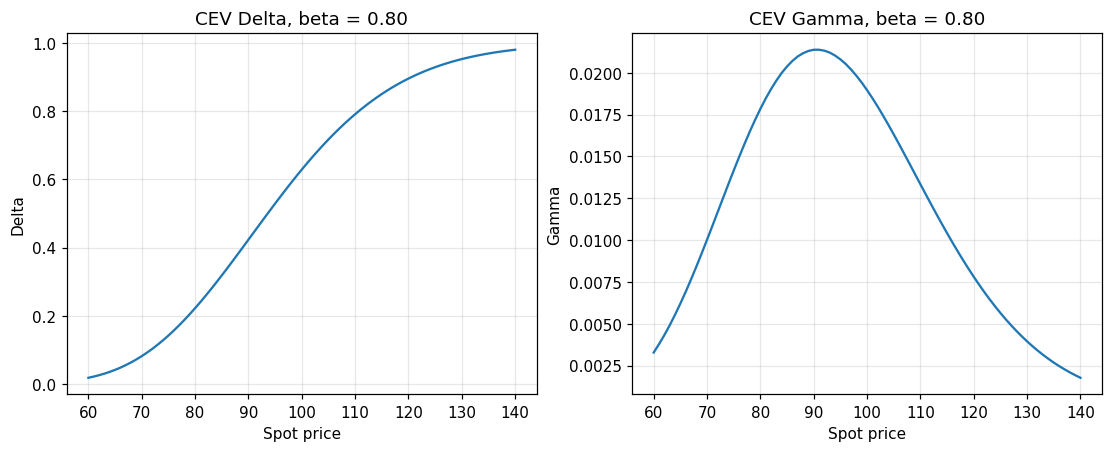

In [21]:
plot_spots = np.arange(60.0, 141.0)
fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.0), layout="constrained")
for index, greek_name in enumerate(["Delta", "Gamma"]):
    interpolated = np.interp(plot_spots, inner_grid, grid_greeks[:, index])
    axes[index].plot(plot_spots, interpolated)
    axes[index].set_title(f"CEV {greek_name}, beta = 0.80")
    axes[index].set_xlabel("Spot price")
    axes[index].set_ylabel(greek_name)
    axes[index].grid(True, alpha=0.3)
plt.show()

### Heston Monte Carlo 가격엔진 wrapper

매 호출에서 같은 seed를 사용하여 common random numbers를 적용합니다. 이 wrapper의 volatility는 초기분산의 제곱근이고, 장기분산 theta는 고정됩니다.

원문: `section09_option_greeks.tex` · Listing 20 · 1147행

In [22]:
def heston_mc_price_engine(
    spot,
    strike,
    maturity,
    rate,
    volatility,
    dividend_yield=0.0,
    option_type="call",
):
    initial_variance = float(volatility) ** 2

    price, _ = monte_carlo_heston_option(
        spot=spot,
        strike=strike,
        maturity=maturity,
        rate=rate,
        initial_variance=initial_variance,
        kappa=2.0,
        theta=0.04,
        vol_of_variance=0.30,
        correlation=-0.70,
        n_paths=200_000,
        n_steps=252,
        seed=2026,
        option_type=option_type,
        dividend_yield=dividend_yield,
    )
    return price

### Heston Delta, Gamma와 초기변동성 Vega

따라서 여기의 Vega는 $\sigma_0=\sqrt{v_0}$에 대한 초기변동성 민감도입니다. Monte Carlo 오차와 bump 크기에 특히 민감한 Gamma를 주의해서 읽으세요.

원문: `section09_option_greeks.tex` · Listing 21 · 1178행

In [23]:
heston_greeks = finite_difference_greeks(
    price_function=heston_mc_price_engine,
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.03,
    volatility=0.20,
    spot_bump=0.50,
    volatility_bump=0.005,
    rate_bump=0.001,
)

print(heston_greeks)

{'delta': 0.6533264613756167, 'gamma': 0.019043213186776597, 'vega': 16.119035075142207, 'theta': -5.2919256011881455, 'rho': 56.08060979600804}


## 마무리 확인

- Theta는 달력시간 증가에 대한 민감도인지 확인했습니다.
- Vega/Rho의 1%p 단위와 원 단위를 구분했습니다.
- 해석적 Greeks, 수치미분, PDE 격자 차분을 비교했습니다.
- Delta hedge는 이산적으로 재조정하므로 잔여 오차가 남습니다.
- Heston의 초기변동성 Vega를 장기분산 $\theta$ 또는 초기분산 $v_0$ 민감도와 구분했습니다.

**추가 연습:** CEV의 beta, Monte Carlo의 경로 수, spot bump를 각각 바꿔서 가격보다 Gamma가 얼마나 민감한지 확인해 보세요.